<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta4_%C3%B6dev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: NVIDIA RTX PRO 6000 Blackwell Server Edition


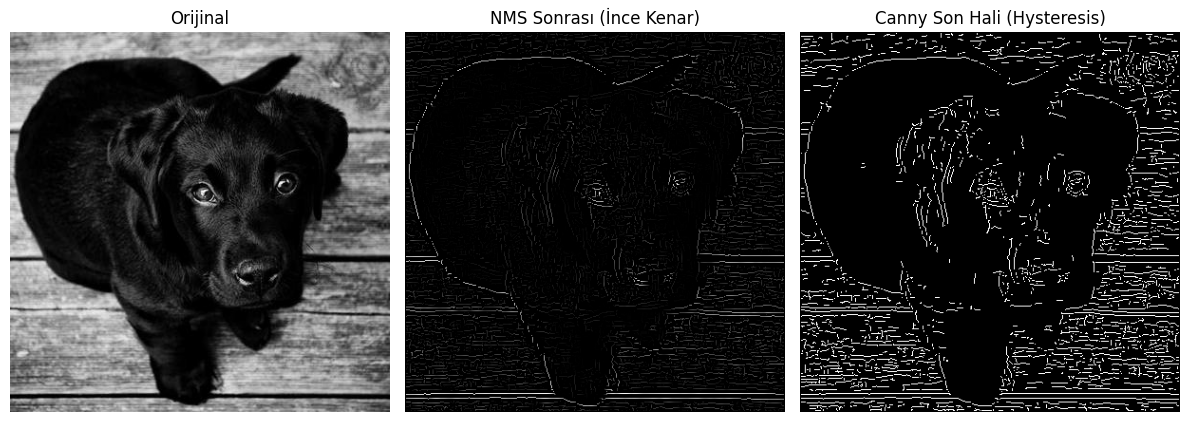

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# 0. Test için örnek bir görüntü indirelim ve griye çevirelim
url = 'https://picsum.photos/id/237/400/400'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_GRAYSCALE)

# -------------------------------------------------------------
# ADIM 1: Gürültü Bastırma (5x5 Gauss Filtresi)
# -------------------------------------------------------------
def apply_gaussian_blur(image):
    # Sabit 5x5 Gauss çekirdeği (sigma = 1)
    kernel = np.array([
        [2,  4,  5,  4,  2],
        [4,  9, 12,  9,  4],
        [5, 12, 15, 12,  5],
        [4,  9, 12,  9,  4],
        [2,  4,  5,  4,  2]
    ], dtype=np.float32)
    kernel /= 159.0 # Normalizasyon

    # Manuel veya OpenCV konvolüzyon (filtreleme matematiksel mantığı için)
    return cv2.filter2D(image, -1, kernel)

# -------------------------------------------------------------
# ADIM 2: Sobel Filtre ile Gradyan Hesaplama
# -------------------------------------------------------------
def compute_gradients(image):
    Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
    Ky = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)

    Ix = cv2.filter2D(image, cv2.CV_64F, Kx)
    Iy = cv2.filter2D(image, cv2.CV_64F, Ky)

    # Gradyan büyüklüğü (Magnitude) ve Yönü (Direction)
    magnitude = np.hypot(Ix, Iy)
    magnitude = magnitude / magnitude.max() * 255 # 0-255 arasına çekme
    direction = np.arctan2(Iy, Ix) * (180 / np.pi) # Açıya çevirme

    return magnitude, direction

# -------------------------------------------------------------
# ADIM 3: Non-Maximum Suppression (İnce Kenar Çizgisi)
# -------------------------------------------------------------
def non_maximum_suppression(magnitude, direction):
    M, N = magnitude.shape
    Z = np.zeros((M, N), dtype=np.float32)
    angle = direction % 180 # Açıları 0-180 arasına indirgeyelim

    for i in range(1, M-1):
        for j in range(1, N-1):
            q = 255
            r = 255

            # Açı bölgelerine göre komşuları kontrol etme (0, 45, 90, 135 derece)
            # 0 derece (Yatay)
            if (0 <= angle[i,j] < 22.5) or (157.5 <= angle[i,j] <= 180):
                q = magnitude[i, j+1]
                r = magnitude[i, j-1]
            # 45 derece
            elif (22.5 <= angle[i,j] < 67.5):
                q = magnitude[i+1, j-1]
                r = magnitude[i-1, j+1]
            # 90 derece (Dikey)
            elif (67.5 <= angle[i,j] < 112.5):
                q = magnitude[i+1, j]
                r = magnitude[i-1, j]
            # 135 derece
            elif (112.5 <= angle[i,j] < 157.5):
                q = magnitude[i-1, j-1]
                r = magnitude[i+1, j+1]

            # Piksel, kendi yönündeki komşularından büyükse tut, değilse sil (0 yap)
            if (magnitude[i,j] >= q) and (magnitude[i,j] >= r):
                Z[i,j] = magnitude[i,j]
            else:
                Z[i,j] = 0

    return Z

# -------------------------------------------------------------
# ADIM 4: Hysteresis Thresholding (Çift Eşikleme ve Bağlama)
# -------------------------------------------------------------
def hysteresis_thresholding(img, lowThresholdRatio=0.05, highThresholdRatio=0.15):
    highThreshold = img.max() * highThresholdRatio
    lowThreshold = highThreshold * lowThresholdRatio

    M, N = img.shape
    res = np.zeros((M, N), dtype=np.int32)

    STRONG = 255
    WEAK = 75

    strong_i, strong_j = np.where(img >= highThreshold)
    weak_i, weak_j = np.where((img <= highThreshold) & (img >= lowThreshold))

    res[strong_i, strong_j] = STRONG
    res[weak_i, weak_j] = WEAK

    # Zayıf kenarları güçlü kenarlara bağlıysa kurtar, değilse sil
    for i in range(1, M-1):
        for j in range(1, N-1):
            if res[i, j] == WEAK:
                if (
                    res[i+1, j-1] == STRONG or res[i+1, j] == STRONG or res[i+1, j+1] == STRONG or
                    res[i-1, j-1] == STRONG or res[i-1, j] == STRONG or res[i-1, j+1] == STRONG or
                    res[i, j-1] == STRONG or res[i, j+1] == STRONG
                ):
                    res[i, j] = STRONG
                else:
                    res[i, j] = 0

    return res.astype(np.uint8)

# -------------------------------------------------------------
# TÜM ADIMLARI ÇALIŞTIRMA
# -------------------------------------------------------------
blurred = apply_gaussian_blur(img)
magnitude, direction = compute_gradients(blurred)
nms_img = non_maximum_suppression(magnitude, direction)
canny_final = hysteresis_thresholding(nms_img)

# Görselleştirme
plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Orijinal'), plt.axis('off')
plt.subplot(1, 3, 2), plt.imshow(nms_img, cmap='gray'), plt.title('NMS Sonrası (İnce Kenar)'), plt.axis('off')
plt.subplot(1, 3, 3), plt.imshow(canny_final, cmap='gray'), plt.title('Canny Son Hali (Hysteresis)'), plt.axis('off')
plt.tight_layout()
plt.show()

Canny algoritması görüntü işlemede "en iyi kenar bulma" yöntemlerinden biri olarak kabul ediliyor. Bunun sebebi tek bir işlem yapıp geçmemesi, birbirini tamamlayan 4 akıllı adımdan oluşmasıdır. Bu belgede her adımın neden şart olduğunu kendi cümlelerimle özetledim.1. Gürültü Bastırma (5x5 Gauss Filtresi) Neden Gereklidir?Resimlerde gözümüzle fark edemediğimiz minik renk oynamaları veya piksel pürüzleri (gürültü) vardır. Eğer resmi doğrudan kenar bulmaya sokarsak, bu minik gürültüleri de kenar sanıp her yeri çizgilerle doldurur.Neden şart? Resmi önce $5 \times 5$ Gauss filtresiyle hafifçe bulanıklaştırarak bu pürüzleri yok ediyoruz. Böylece algoritma sadece gerçek nesne sınırlarına odaklanıyor.2. Sobel Filtre ile Gradyan Hesaplama Neden Gereklidir?Kenar dediğimiz şey aslında piksellerin parlaklığının ani olarak değiştiği yerdir.Neden şart? Sobel filtresi kullanarak resmin hem yatayda ($X$) hem dikeyde ($Y$) ne kadar değiştiğini (türevini) hesaplıyoruz. Bu sayede kenarın hem şiddetini (ne kadar belirgin olduğunu) hem de yönünü (sağa mı, sola mı, yukarı mı dönük olduğunu) matematiksel olarak bulmuş oluyoruz.3. Non-Maximum Suppression (NMS - Piksel İnceltme) Neden Gereklidir?Sobel veya diğer filtreler kenarları bulur bulmasına ama çıkardığı kenar çizgileri genelde 3-4 piksel kalınlığında kalın çizgiler olur. Bu da net bir sınır çizgisinden ziyade boyalı bir yola benzer.Neden şart? NMS adımı, o kalın kenar çizgilerinin tam ortasındaki en keskin pikseli seçer, sağındaki ve solundaki sönük pikselleri sıfırlar. Böylece kalın çizgiler tıraşlanır ve tek piksel kalınlığında tertemiz, ince bir çizgi haline gelir.4. Hysteresis Thresholding (Çift Eşikleme ve Bağlama) Neden Gereklidir?İnceleme bittikten sonra bile bazı yerlerde kesik kesik çizgiler veya arka plandaki soluk gürültüler kalabilir. Tek bir eşik değeri (threshold) kullanmak bu sorunu çözmez; çünkü eşiği yüksek tutsak gerçek kenarlar kopar, düşük tutsak gereksiz gürültüler içeri girer.Neden şart? Canny burada iki farklı eşik (alt ve üst) kullanır:Güçlü kenarlar: Kesinlikle kalması gereken net sınırlardır.Zayıf kenarlar: Şüpheli sınırlardır.Hysteresis adımı şunu yapar: Eğer o zayıf kenar, güçlü bir kenara bağlanıyorsa "demek ki bu da nesnenin devamı" diyerek onu kurtarır; hiçbir yere bağlanmıyorsa tamamen siler atar. Böylece kenarlar kopmadan, eksiksiz bir şekilde ortaya çıkar.